In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
from pathlib import Path
Path('figures').mkdir(exist_ok=True)

Matplotlib created a temporary cache directory at /tmp/matplotlib-osfp51kq because the default path (/tmp/mpl) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
df = pd.read_csv(r'../pre-calculated_data/nanopore.csv')
df

,Sample,Total GB,N50 length,Mean Q,Site,Original_sample_name
0,CPSNJ01,45.386270,12017,15.8,NanJing_8,CPSNJ01_350
1,CPSNJ02,57.192760,15910,15.7,NanJing_8,CPSNJ02_350
2,CPSNJ03,46.479399,16752,16.0,NanJing_8,CPSNJ03_350
3,CPSNJ04,71.459105,17489,16.1,NanJing_8,CPSNJ04_350
4,CPSNJ08,48.708406,10742,15.0,NanJing_8,CPSNJ08_350
5,CPSNJ09,67.587256,17853,15.7,NanJing_8,CPSNJ09_350
6,CPSNJ10,59.134384,18330,15.7,NanJing_8,CPSNJ10_350
7,CPSNJ11,54.003233,19505,15.7,NanJing_8,CPSNJ11_350
8,CPSNJ13,47.460343,19467,15.9,NanJing_8,CPSNJ13_350
9,CPSNJ14,54.746032,19967,15.9,NanJing_8,CPSNJ14_350


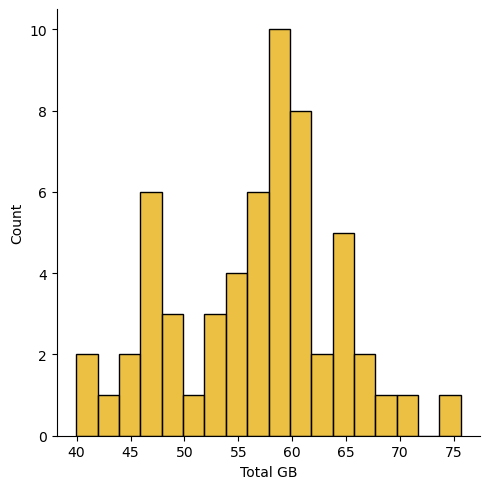

In [3]:
sns.displot(data=df,
            x='Total GB',
            color='#e6ab02',binwidth=2)

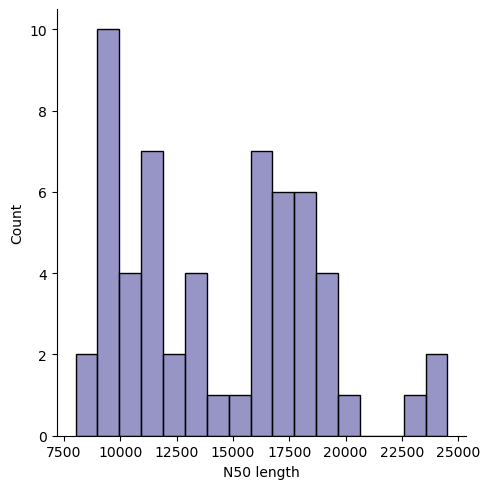

In [4]:
sns.displot(data=df,
            x='N50 length',
            color='#7570b3',binwidth=1000)

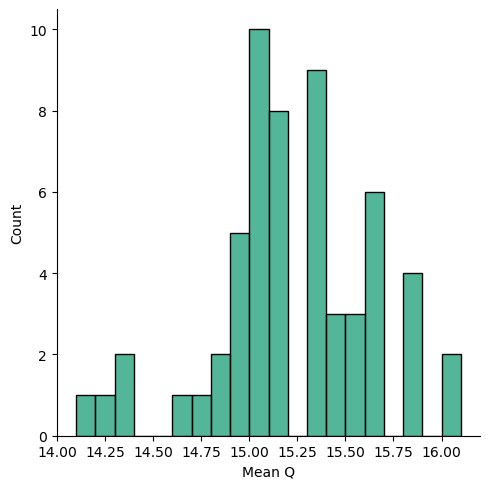

In [5]:
sns.displot(data=df,
            x='Mean Q',
            color='#1b9e77',binwidth=0.1)

In [6]:
df = pd.read_csv('../pre-calculated_data/alpha_diversity.csv', index_col=0)
df = df.drop(['11_350', '4_350'])
df

,chao1,simpson,shannon,Site,Ecosystem
sample,,,,,
10_350,4292.338707,0.998740,7.294697,Shanghai,Urban
12_350,4551.470977,0.999309,7.577652,Shanghai,Urban
13_350,4270.553051,0.998893,7.384294,Shanghai,Urban
14_350,6367.125360,0.999313,7.687506,Shanghai,Urban
15_350,5605.248342,0.999008,7.521860,Shanghai,Urban
...,...,...,...,...,...
SRR25158533,3215.899405,0.995741,6.777820,SMAG,Agricultural Land
SRR25158534,5145.542483,0.999315,7.493605,SMAG,Agricultural Land
SRR25158535,3455.844418,0.998934,7.176543,SMAG,Wetland


In [7]:
df["Type"] = df['Ecosystem']+" - "+df['Site']
custom_dict =  {"Urban - Nanjing":0, "Urban - Shanghai":1, 'Bare Land - SMAG':6, 'Wetland - SMAG':5,
                'Agricultural Land - SMAG':2, 'Grassland - SMAG':3, 'Forest - SMAG':4, "Canine Gut - Dog":7}
df = df.sort_values(by=['Type'], key=lambda x: x.map(custom_dict))
df

,chao1,simpson,shannon,Site,Ecosystem,Type
sample,,,,,,
SNJ04_350,5889.713599,0.999447,7.786089,Nanjing,Urban,Urban - Nanjing
SNJ03_350,5662.624530,0.999276,7.642770,Nanjing,Urban,Urban - Nanjing
SNJ02_350,6030.284843,0.998955,7.690642,Nanjing,Urban,Urban - Nanjing
SNJ01_350,6253.765372,0.999415,7.792893,Nanjing,Urban,Urban - Nanjing
SNJ11_350,5015.684396,0.999262,7.546213,Nanjing,Urban,Urban - Nanjing
...,...,...,...,...,...,...
D008_350,1990.761657,0.877091,3.153223,Dog,Canine Gut,Canine Gut - Dog
D010_350,1046.628579,0.926737,3.394907,Dog,Canine Gut,Canine Gut - Dog
D011_350,1025.302104,0.887036,3.202763,Dog,Canine Gut,Canine Gut - Dog


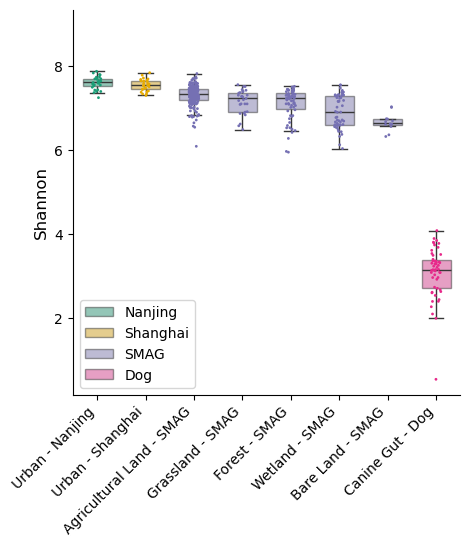

In [8]:
custom_palette = {
    'Nanjing': '#1b9e77',
    'Shanghai': '#e6ab02',
    'SMAG': '#7570b3',
    'Dog': '#e7298a',
}

fig, ax = plt.subplots(figsize=(5, 5))
sns.boxplot(data=df, x="Type", y="shannon", color='white', hue="Site", 
             palette=custom_palette,boxprops=dict(alpha=0.5),
            showfliers=False, ax=ax, width=0.6)

sns.stripplot(data=df, x="Type", y="shannon", hue="Site",
             palette=custom_palette, ax=ax,size=2, jitter=True,legend=False)

y_max = df['shannon'].max()
y_min = df['shannon'].min()
vertical_offset = 0.1 * (y_max - y_min)
current_level = 1  

ax.set_ylim(top=y_max + vertical_offset * (current_level + 1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylabel('Shannon', fontsize=12)
ax.set_xlabel('')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[0:4], labels=labels[0:4], loc="lower left")
plt.xticks(rotation=45, ha='right')
plt.savefig('figures/fig1c.svg')

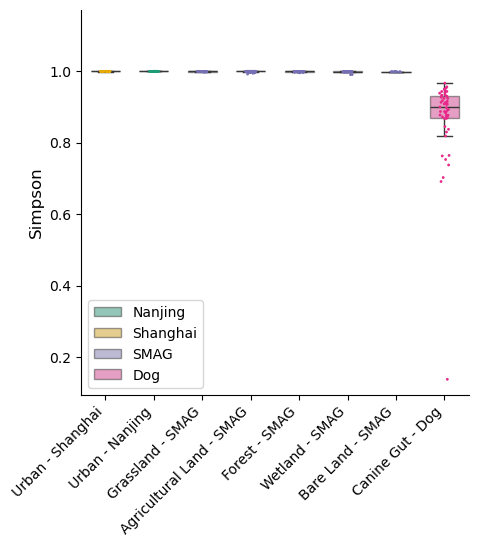

In [9]:
custom_palette = {
    'Nanjing': '#1b9e77',
    'Shanghai': '#e6ab02',
    'SMAG': '#7570b3',
    'Dog': '#e7298a',
}

fig, ax = plt.subplots(figsize=(5, 5))
sns.boxplot(data=df, x="Type", y="simpson", color='white', hue="Site", 
             palette=custom_palette,boxprops=dict(alpha=0.5),
            showfliers=False, ax=ax, width=0.6, order=["Urban - Shanghai","Urban - Nanjing",'Grassland - SMAG','Agricultural Land - SMAG','Forest - SMAG', 
                                                       'Wetland - SMAG','Bare Land - SMAG', "Canine Gut - Dog"])

sns.stripplot(data=df, x="Type", y="simpson", hue="Site",
             palette=custom_palette, ax=ax,size=2, jitter=True, order=["Urban - Shanghai","Urban - Nanjing",'Grassland - SMAG','Agricultural Land - SMAG','Forest - SMAG', 
                                                       'Wetland - SMAG','Bare Land - SMAG', "Canine Gut - Dog"],legend=False)

tukey = pairwise_tukeyhsd(endog=df['simpson'], groups=df['Type'], alpha=0.05)
summary = tukey.summary()

significant_pairs = []
for i in range(1, len(summary.data)):
    row = summary.data[i]
    if float(row[3]) < 0.05:
        if "Canine Gut - Dog" not in [row[0], row[1]]:
            group1 = row[0]
            group2 = row[1]
            p_val = float(row[3])
            significant_pairs.append( (group1, group2, p_val) )

group_order = df['Type'].unique()
x_positions = {group: idx for idx, group in enumerate(group_order)}

y_max = df['simpson'].max()
y_min = df['simpson'].min()
vertical_offset = 0.1 * (y_max - y_min)
current_level = 1  
line_props = {'color': 'black', 'linewidth': 1, 'transform': ax.transData}
for pair in significant_pairs:
    group1, group2, p_val = pair
    x1 = x_positions[group1]
    x2 = x_positions[group2]
    if p_val < 0.001:
        symbol = '***'
    elif p_val < 0.01:
        symbol = '**'
    elif p_val < 0.05:
        symbol = '*'
    else:
        continue
    y_top = y_max + (vertical_offset * current_level)
    y_line = y_top - 0.1 * vertical_offset
    ax.plot([x1, x1, x2, x2], 
            [y_line, y_top, y_top, y_line], **line_props)
    ax.text((x1+x2)/2, y_top, symbol, 
            ha='center', va='bottom', 
            fontsize=12, color='black')
    current_level += 1 

ax.set_ylim(top=y_max + vertical_offset * (current_level + 1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylabel('Simpson', fontsize=12)
ax.set_xlabel('')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[0:4], labels=labels[0:4], loc="lower left")
plt.xticks(rotation=45, ha='right')
plt.savefig('figures/fig1d.svg')